In [14]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub

/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/barbell biceps curl/barbell biceps curl_1.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/barbell biceps curl/barbell biceps curl_10.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/barbell biceps curl/barbell biceps curl_11.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/barbell biceps curl/barbell biceps curl_12.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/barbell biceps curl/barbell biceps curl_13.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/barbell biceps curl/barbell biceps curl_14.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/barbell biceps curl/barbell biceps curl_15.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/barbell biceps curl/barbell biceps curl_16.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/barbell biceps curl/barbell biceps curl_17.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfi

In [15]:
!pip install -q mediapipe


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.


In [16]:
import mediapipe as mp
print(mp.__version__)


I0000 00:00:1794553127.843698      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794553145.431656      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


1.2.3


## Downloads the pretrained pose model file into /kaggle/working.

In [25]:
!wget -q -O pose_landmarker_full.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task


In [26]:
import kagglehub

DATA_DIR = kagglehub.dataset_download('hasyimabdillah/workoutfitness-video')
print(DATA_DIR)

/kaggle/input/datasets/hasyimabdillah/workoutfitness-video


In [27]:
import os

squat_videos = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        path = os.path.join(root, f)
        if 'squat' in path.lower() and f.lower().endswith(('.mp4', '.mov', '.avi')):
            squat_videos.append(path)
# Walks through every folder in your Kaggle inputs.
# Keeps only video files that have "squat" somewhere in their path.

print(len(squat_videos), 'squat videos found')
for v in squat_videos[:5]:
    print(v)
# Shows how many were found and the first 5 paths, so you can check it worked.

29 squat videos found
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/squat/squat_1.MOV
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/squat/squat_10.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/squat/squat_11.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/squat/squat_12.mp4
/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/squat/squat_13.mp4


In [28]:
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

VIDEO_PATH = squat_videos[0]
print('Using:', VIDEO_PATH)

options = vision.PoseLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path='pose_landmarker_full.task'),
    running_mode=vision.RunningMode.VIDEO,
    num_poses=1,
)
landmarker = vision.PoseLandmarker.create_from_options(options)

CONNECTIONS = [
    (11, 12), (11, 13), (13, 15), (12, 14), (14, 16),   # shoulders + arms
    (11, 23), (12, 24), (23, 24),                       # torso
    (23, 25), (25, 27), (24, 26), (26, 28),             # legs
]

def draw_skeleton(frame, landmarks):
    h, w = frame.shape[:2]
    pts = [(int(lm.x * w), int(lm.y * h)) for lm in landmarks]
    for a, b in CONNECTIONS:
        cv2.line(frame, pts[a], pts[b], (0, 255, 0), 3)
    for i in range(11, 29):
        cv2.circle(frame, pts[i], 5, (0, 0, 255), -1)


Using: /kaggle/input/datasets/hasyimabdillah/workoutfitness-video/squat/squat_1.MOV


INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x79a550003f00, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x79a54c002990, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.


In [29]:
cap = cv2.VideoCapture(VIDEO_PATH)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
# Opens the video and reads its frames per second, size and total frame count.
# "or 30" = a safe default in case the video doesn't report its fps.

out = cv2.VideoWriter('squat_pose.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))
sample_at = set(np.linspace(0, total - 1, 4, dtype=int))
rows, samples = [], []
frame_idx = 0
# out = a new video file where we save frames with the skeleton drawn on.
# sample_at = 4 evenly spaced frame numbers, saved as preview pictures.
# rows = body point numbers for every frame (they become the CSV).

while True:
    ok, frame = cap.read()
    if not ok:
        break
    # Reads the next frame. When the video ends, ok = False and the loop stops.

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    timestamp_ms = int(frame_idx * 1000 / fps)
    result = landmarker.detect_for_video(mp_image, timestamp_ms)
    # OpenCV uses BGR colour order, MediaPipe wants RGB, so we convert.
    # VIDEO mode needs a time in milliseconds for each frame, always increasing.
    # result.pose_landmarks = a list of people found, each with 33 points.

    if result.pose_landmarks:
        lms = result.pose_landmarks[0]
        draw_skeleton(frame, lms)
        rows.append([frame_idx] + [v for lm in lms for v in (lm.x, lm.y, lm.z, lm.visibility)])
    # If a person was found: draw the skeleton and save the frame number + all 33 points.
    # Each point has x, y, z (depth) and visibility (how sure the model is the point is visible).

    out.write(frame)
    if frame_idx in sample_at:
        samples.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    frame_idx += 1
    # Saves the drawn frame into the new video and keeps the 4 preview frames.

cap.release()
out.release()
landmarker.close()
print(f'{frame_idx} frames processed, pose found in {len(rows)}')
# Closes everything and prints a summary. Ideally both numbers are (almost) the same.

W0000 00:00:1794553191.616252     170 inference_runner_litert.cc:1433] Input tensor memory is not aligned according to LiteRt's memory alignment requirements. Reallocating memory and copying data.
W0000 00:00:1794553191.695897     171 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.
INFO: [accelerator_registry.cc:43] DestroyAccelerator: ptr=0x79a550003f00, name=CpuAccelerator
INFO: [accelerator_registry.cc:43] DestroyAccelerator: ptr=0x79a54c002990, name=CpuAccelerator


587 frames processed, pose found in 587


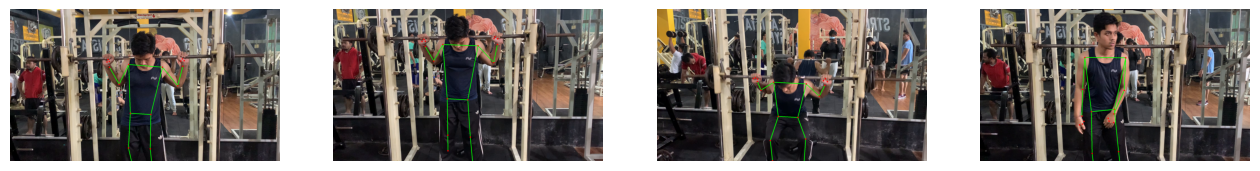

In [30]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(samples), figsize=(16, 5))
for ax, img in zip(np.atleast_1d(axes), samples):
    ax.imshow(img)
    ax.axis('off')
plt.show()


In [31]:
import pandas as pd

cols = ['frame'] + [f'{i}_{k}' for i in range(33) for k in ('x', 'y', 'z', 'vis')]
df = pd.DataFrame(rows, columns=cols)
df.to_csv('squat_landmarks.csv', index=False)
df.head()
# Turns the saved points into a table: 1 row per frame, 1 + 33×4 = 133 columns.
# Column names look like "25_y" = point 25 (left knee), y position.
# Saves it as squat_landmarks.csv; step 4 uses it to compute knee angles.

,frame,0_x,0_y,0_z,0_vis,1_x,1_y,1_z,1_vis,2_x,...,30_z,30_vis,31_x,31_y,31_z,31_vis,32_x,32_y,32_z,32_vis
0,0,0.493471,0.362655,-0.367422,0.999973,0.501198,0.339666,-0.365959,0.999977,0.507495,...,0.240989,0.145138,0.533644,1.144405,0.119548,0.167998,0.455645,1.134923,0.161186,0.097064
1,1,0.493457,0.364479,-0.401538,0.999970,0.501018,0.341419,-0.407021,0.999975,0.507248,...,0.287751,0.141552,0.532176,1.213883,0.020569,0.163739,0.455509,1.201849,0.169877,0.095566
2,2,0.492875,0.366277,-0.392503,0.999965,0.500071,0.343240,-0.394659,0.999969,0.506193,...,0.287427,0.135995,0.530704,1.274758,-0.022944,0.155698,0.457032,1.266957,0.169724,0.090339
3,3,0.492106,0.370113,-0.433731,0.999953,0.499003,0.348122,-0.438768,0.999959,0.505062,...,0.351095,0.130707,0.538542,1.263284,0.049672,0.149720,0.459083,1.247116,0.242254,0.085544
4,4,0.492090,0.377160,-0.462383,0.999940,0.498903,0.355994,-0.469637,0.999948,0.504915,...,0.378178,0.125237,0.542071,1.258150,0.136096,0.141858,0.464229,1.247017,0.267645,0.079902


## Joint angles + rule-based squat rep counter

In [33]:
import numpy as np
import pandas as pd

df = pd.read_csv("squat_landmarks.csv")
print(df.shape)


def joint_angle(df, a, b, c, w, h):
    ax, ay = df[f'{a}_x'] * w, df[f'{a}_y'] * h
    bx, by = df[f'{b}_x'] * w, df[f'{b}_y'] * h
    cx, cy = df[f'{c}_x'] * w, df[f'{c}_y'] * h

    v1 = np.stack([ax - bx, ay - by], axis=1)
    v2 = np.stack([cx - bx, cy - by], axis=1)

    cos = (v1 * v2).sum(axis=1) / (np.linalg.norm(v1, axis=1) * np.linalg.norm(v2, axis=1) + 1e-8)
    return np.degrees(np.arccos(np.clip(cos, -1, 1)))

(587, 133)


In [34]:
left_knee  = joint_angle(df, 23, 25, 27, w, h)
right_knee = joint_angle(df, 24, 26, 28, w, h)
# Knee angle for each leg: hip → knee → ankle.
# Left = points 23, 25, 27. Right = points 24, 26, 28.

left_vis  = df[['25_vis', '27_vis']].mean().mean()
right_vis = df[['26_vis', '28_vis']].mean().mean()
knee = left_knee if left_vis >= right_vis else right_knee
side = 'left' if left_vis >= right_vis else 'right'
print(f'Using {side} leg (visibility L={left_vis:.2f}, R={right_vis:.2f})')
# In a side view, one leg is hidden behind the other, so its points are guesses.
# We pick the leg the model is more confident about (higher average visibility).

knee = pd.Series(knee).rolling(5, center=True, min_periods=1).mean().to_numpy()
print(f'Angle range: {knee.min():.0f}° – {knee.max():.0f}°')
# Smooths the angle by averaging each frame with its 2 neighbours on each side, which removes jitter.
# The range shows how low the person went and how straight they stood.

Using left leg (visibility L=0.64, R=0.58)
Angle range: 108° – 180°


In [35]:
def count_reps(angles, down_thr=100, up_thr=160):
    state = 'up'
    reps = []
    start = None
    # Starts in the "up" state (standing). reps will hold (start_frame, end_frame) for each rep.

    for i, a in enumerate(angles):
        if state == 'up' and a < down_thr:
            state = 'down'
            start = i
        # Knee bent below 100° → the person reached the bottom. Remember where this rep started.

        elif state == 'down' and a > up_thr:
            state = 'up'
            reps.append((start, i))
        # Knee straight again above 160° → the person stood up, so one full rep is complete.

    return reps

reps = count_reps(knee)
print(f'✅ {len(reps)} squats counted')
print(reps)
# Runs the counter on our smoothed knee angles and prints the count + the frames of each rep.
# Step 5 uses these frame ranges to cut the video into single reps for the form checker.

✅ 0 squats counted
[]


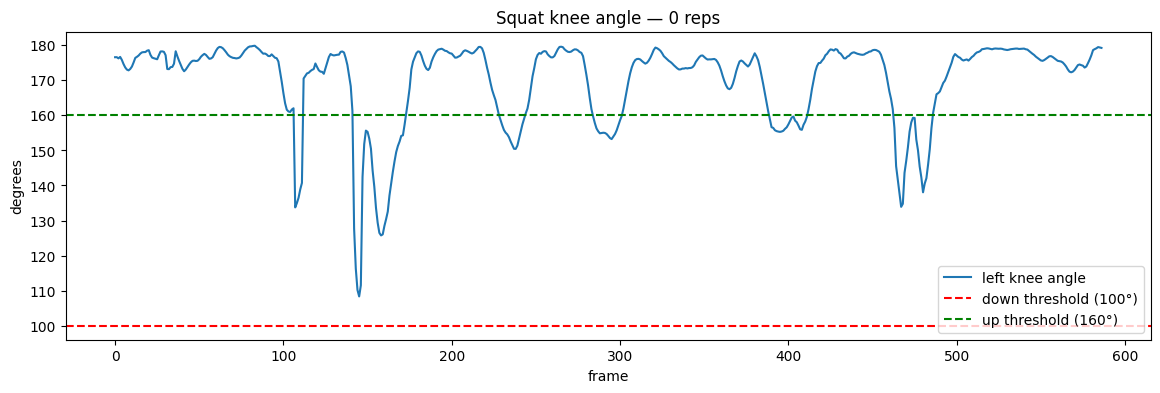

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))
plt.plot(df['frame'], knee, label=f'{side} knee angle')
plt.axhline(100, color='red', linestyle='--', label='down threshold (100°)')
plt.axhline(160, color='green', linestyle='--', label='up threshold (160°)')
# Draws the knee angle over time as a line, plus the two thresholds as dashed lines.

for n, (s, e) in enumerate(reps, 1):
    plt.axvspan(df['frame'].iloc[s], df['frame'].iloc[e], color='orange', alpha=0.2)
    plt.text(df['frame'].iloc[s], 175, f'#{n}')
# Shades each counted rep in orange and numbers it, so you can see if the count matches the dips.

plt.xlabel('frame')
plt.ylabel('degrees')
plt.title(f'Squat knee angle — {len(reps)} reps')
plt.legend(loc='lower right')
plt.show()
# Labels and shows the chart. Each squat should look like one "U"-shaped dip.

### Watch the example video

In [37]:
print(VIDEO_PATH)
# Shows which dataset video was used.

!ffmpeg -y -loglevel error -i squat_pose.mp4 -vcodec libx264 -pix_fmt yuv420p -preset veryfast squat_pose_web.mp4
# Converts our skeleton video into a format the browser can play (H.264).
# The mp4v format from cell 5 often won't play inside a notebook.

from IPython.display import Video
Video('squat_pose_web.mp4', embed=True, width=600)
# Plays the video with the skeleton drawn on, right under this cell.

/kaggle/input/datasets/hasyimabdillah/workoutfitness-video/squat/squat_1.MOV


In [38]:
from scipy.signal import find_peaks, peak_widths

def px(df, i, axis):
    return df[f'{i}_{axis}'] * (w if axis == 'x' else h)
# Turns a point's 0–1 position into pixels (unchanged).

for name, i in [('L hip', 23), ('R hip', 24), ('L knee', 25), ('R knee', 26)]:
    print(f'{name:<7} visibility: {df[f"{i}_vis"].mean():.2f}')
# Diagnostic: checks that the model can see the hips and knees well.

sh_x = (px(df, 11, 'x') + px(df, 12, 'x')) / 2
sh_y = (px(df, 11, 'y') + px(df, 12, 'y')) / 2
hip_x = (px(df, 23, 'x') + px(df, 24, 'x')) / 2
hip_y = (px(df, 23, 'y') + px(df, 24, 'y')) / 2
knee_y = (px(df, 25, 'y') + px(df, 26, 'y')) / 2
torso = np.hypot(sh_x - hip_x, sh_y - hip_y)
# Middle of the shoulders, hips and knees, plus torso length (shoulders → hips) for every frame.

parts = pd.DataFrame({'hip_y': hip_y, 'knee_y': knee_y, 'torso': torso})
vis = df[['11_vis', '12_vis', '23_vis', '24_vis', '25_vis', '26_vis']].min(axis=1)
good = vis > 0.3
parts = parts.where(good).interpolate(limit_direction='both')
print(f'\nFrames trusted: {good.mean():.0%}')
# Groups the three measurements into one table, so we clean them all at once.
# Frames where shoulders, hips or knees are unsure get blanked out and filled in from their neighbours.

torso_len = parts['torso'].rolling(int(fps * 4), center=True, min_periods=1).median()
gap = (parts['knee_y'] - parts['hip_y']) / torso_len
depth = (1 - gap).rolling(5, center=True, min_periods=1).mean()
signal = depth.to_numpy()
# gap = how far the hips are ABOVE the knees, measured in torso lengths (y grows downward, so knee_y - hip_y).
# depth = 1 - gap → small when standing, ~1.0 when hips reach knee height (parallel), >1.0 = below parallel.
# Both points move together when the camera moves, so camera shake cancels out.

print(f'Depth range: {signal.min():.2f} → {signal.max():.2f}')
# Standing should be roughly 0.0–0.3 and the deepest squat close to 1.0.

L hip   visibility: 1.00
R hip   visibility: 1.00
L knee  visibility: 0.87
R knee  visibility: 0.81

Frames trusted: 99%
Depth range: 0.05 → 0.65


In [39]:
def count_reps_peaks(signal, fps, min_drop=0.15, min_gap_sec=0.8, min_sec=0.4):
    peaks, props = find_peaks(signal, prominence=min_drop, distance=int(fps * min_gap_sec))
    # Same as before, but min_drop is lowered 0.25 → 0.15
    # so squats where the person doesn't fully stand up in between can still be separated.

    widths = peak_widths(signal, peaks, rel_height=0.5)
    reps, depths, bottoms = [], [], []
    for p, l, r, prom in zip(peaks, widths[2], widths[3], props['prominences']):
        if (r - l) / fps >= min_sec:
            reps.append((int(l), int(r)))
            depths.append(prom)
            bottoms.append(int(p))
    return reps, depths, bottoms
    # rel_height 0.9 → 0.5: each rep is now marked from halfway down to halfway up.
    # Before, rep 1 stretched from frame 4 to 301 because it reached all the way down to the lowest point.
    # NEW: bottoms = the frame where the hips were lowest in each rep (used in cell 15).

reps, depths, bottoms = count_reps_peaks(signal, fps)
print(f'✅ {len(reps)} squats counted')
for n, ((s, e), d, b) in enumerate(zip(reps, depths, bottoms), 1):
    print(f'Rep {n}: frames {s}–{e}, bottom at {b}, hip drop = {d:.2f} torso lengths')

✅ 6 squats counted
Rep 1: frames 94–107, bottom at 101, hip drop = 0.27 torso lengths
Rep 2: frames 146–175, bottom at 163, hip drop = 0.45 torso lengths
Rep 3: frames 222–250, bottom at 238, hip drop = 0.47 torso lengths
Rep 4: frames 281–314, bottom at 295, hip drop = 0.59 torso lengths
Rep 5: frames 384–415, bottom at 402, hip drop = 0.37 torso lengths
Rep 6: frames 464–497, bottom at 477, hip drop = 0.38 torso lengths


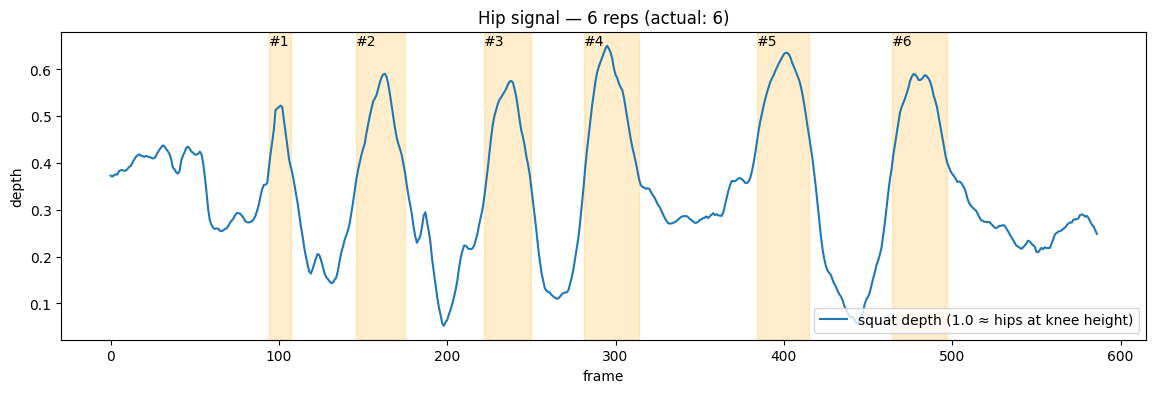

In [40]:
plt.figure(figsize=(14, 4))
plt.plot(df['frame'], signal, label='squat depth (1.0 ≈ hips at knee height)')
for n, ((s, e), d) in enumerate(zip(reps, depths), 1):
    plt.axvspan(df['frame'].iloc[s], df['frame'].iloc[e], color='orange', alpha=0.2)
    plt.text(df['frame'].iloc[s], signal.max(), f'#{n}')
# Draws the hip signal and shades + numbers each counted rep.

plt.xlabel('frame')
plt.ylabel('depth')
plt.title(f'Hip signal — {len(reps)} reps (actual: 6)')
plt.legend(loc='lower right')
plt.show()

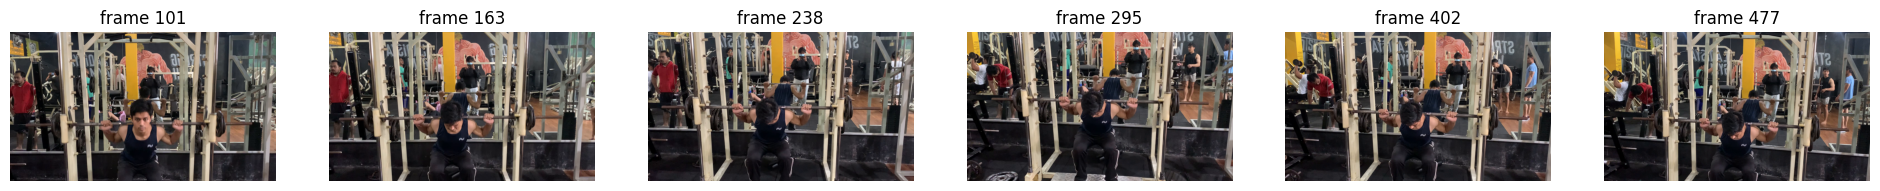

In [41]:
cap = cv2.VideoCapture(VIDEO_PATH)
imgs = []
for b in bottoms:
    f = int(df['frame'].iloc[b])
    cap.set(cv2.CAP_PROP_POS_FRAMES, f)
    ok, frame = cap.read()
    if ok:
        imgs.append((f, cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))
cap.release()
# Opens the ORIGINAL video and jumps straight to the "bottom" frame of each detected rep.
# Saves those frames as pictures (converted from BGR to RGB for matplotlib).

if imgs:
    fig, axes = plt.subplots(1, len(imgs), figsize=(4 * len(imgs), 5))
    for ax, (f, img) in zip(np.atleast_1d(axes), imgs):
        ax.imshow(img)
        ax.set_title(f'frame {f}')
        ax.axis('off')
    plt.show()
# Shows all the bottom frames side by side, each labelled with its frame number.
# If the counter is right, every picture should show someone at the bottom of a squat.

## Collect + label the dataset (squats, curls, good/bad)

In [42]:
import os, random, subprocess
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from scipy.signal import find_peaks, peak_widths
from IPython.display import Video
# Everything we need in one place, so this cell works even after a restart.

MODEL_PATH = 'pose_landmarker_full.task'
COLS = ['frame'] + [f'{i}_{k}' for i in range(33) for k in ('x', 'y', 'z', 'vis')]
# The model file from cell 2 and the CSV column names from step 3.


def extract_landmarks(video_path, stride=1):
    options = vision.PoseLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=MODEL_PATH),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1,
    )
    landmarker = vision.PoseLandmarker.create_from_options(options)
    # A fresh pose model for every video, because VIDEO mode needs timestamps to start again from 0.

    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    rows, idx = [], 0
    # Opens the video and reads its fps and size (same as cell 5).

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if idx % stride == 0:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
            result = landmarker.detect_for_video(image, int(idx * 1000 / fps))
            if result.pose_landmarks:
                lms = result.pose_landmarks[0]
                rows.append([idx] + [v for lm in lms for v in (lm.x, lm.y, lm.z, lm.visibility)])
            else:
                rows.append([idx] + [np.nan] * 132)
        idx += 1
    # stride=2 → only every 2nd frame is analysed, which makes it ~2× faster. Squats are slow, so nothing is lost.
    # NEW: if no person is found, we save an empty (NaN) row instead of skipping it,
    # so the timeline stays even and the gap gets filled in later.

    cap.release()
    landmarker.close()
    return pd.DataFrame(rows, columns=COLS), fps / stride, w, h, idx / fps
    # Returns: the points table, the EFFECTIVE fps (e.g. 30 / 2 = 15), the video size and its length in seconds.


def squat_depth(df, w, h, fps):
    P = lambda i, a: df[f'{i}_{a}'] * (w if a == 'x' else h)
    sh_x, sh_y = (P(11, 'x') + P(12, 'x')) / 2, (P(11, 'y') + P(12, 'y')) / 2
    hip_x, hip_y = (P(23, 'x') + P(24, 'x')) / 2, (P(23, 'y') + P(24, 'y')) / 2
    knee_y = (P(25, 'y') + P(26, 'y')) / 2
    # Middle of the shoulders, hips and knees in pixels (same as cell 12).

    parts = pd.DataFrame({'hip_y': hip_y, 'knee_y': knee_y, 'torso': np.hypot(sh_x - hip_x, sh_y - hip_y)})
    good = df[['11_vis', '12_vis', '23_vis', '24_vis', '25_vis', '26_vis']].min(axis=1) > 0.3
    if good.sum() < 10:
        return None, good.mean()
    parts = parts.where(good).interpolate(limit_direction='both')
    # Same cleaning as before. If fewer than 10 frames can be trusted, we give up on this video (return None).

    torso_len = parts['torso'].rolling(max(int(fps * 4), 1), center=True, min_periods=1).median()
    smooth = max(3, round(fps * 0.17))
    depth = (1 - (parts['knee_y'] - parts['hip_y']) / torso_len).rolling(smooth, center=True, min_periods=1).mean()
    return depth.to_numpy(), good.mean()
    # The same depth signal as cell 12.
    # smooth = ~0.17 s of frames, so smoothing is the same however many fps the video has.


def count_reps_peaks(signal, fps, min_drop=0.15, min_gap_sec=0.8, min_sec=0.4):
    peaks, props = find_peaks(signal, prominence=min_drop, distance=max(int(fps * min_gap_sec), 1))
    widths = peak_widths(signal, peaks, rel_height=0.5)
    reps, depths = [], []
    for l, r, prom in zip(widths[2], widths[3], props['prominences']):
        if (r - l) / fps >= min_sec:
            reps.append((int(l), int(r)))
            depths.append(prom)
    return reps, depths
    # Exactly the counter from cell 13 that got 6/6.


def count_squats(video_path):
    df, fps, w, h, dur = extract_landmarks(video_path)
    depth, trusted = squat_depth(df, w, h, fps)
    if depth is None:
        return {'count': 0, 'reps': [], 'depth': None, 'fps': fps, 'trusted': trusted, 'sec': dur}
    reps, depths = count_reps_peaks(depth, fps)
    return {'count': len(reps), 'reps': reps, 'depth': depth, 'fps': fps, 'trusted': trusted, 'sec': dur}
    # 🎯 The whole pipeline in one call: video in → rep count out.
    # Later, this same logic moves into your app.

In [43]:
import os, sys
from contextlib import contextmanager

@contextmanager
def quiet():
    sys.stdout.flush()
    sys.stderr.flush()
    devnull = os.open(os.devnull, os.O_WRONLY)
    saved = os.dup(2)
    os.dup2(devnull, 2)
    try:
        yield
    finally:
        os.dup2(saved, 2)
        os.close(devnull)
        os.close(saved)
        
random.seed(42)
batch = random.sample(squat_videos, min(15, len(squat_videos)))
# Same 15 videos as before (seed 42).

results = []
for i, path in enumerate(batch):
    with quiet():
        r = count_squats(path)
    r['video'] = os.path.basename(path)
    results.append(r)
    print(f'[{i:2}] {r["video"][:35]:<35} | {r["sec"]:4.0f}s | trusted {r["trusted"]:4.0%} | counted {r["count"]}')
# The only change from before: count_squats runs inside "with quiet():".
# Our print() uses channel 1 (stdout), which isn't muted, so you still see one clean line per video.

res = pd.DataFrame(results)

[ 0] squat_28.mp4                        |   13s | trusted  12% | counted 2
[ 1] squat_12.mp4                        |    5s | trusted  48% | counted 1
[ 2] squat_1.MOV                         |   20s | trusted  99% | counted 6
[ 3] squat_4.MOV                         |   20s | trusted 100% | counted 4
[ 4] squat_17.mp4                        |    4s | trusted  58% | counted 1
[ 5] squat_16.mp4                        |    2s | trusted 100% | counted 1
[ 6] squat_6.MOV                         |   22s | trusted 100% | counted 4
[ 7] squat_13.mp4                        |    5s | trusted  53% | counted 2
[ 8] squat_8.mp4                         |    4s | trusted 100% | counted 1
[ 9] squat_25.mp4                        |   11s | trusted  85% | counted 3
[10] squat_11.mp4                        |    6s | trusted 100% | counted 1
[11] squat_21.mp4                        |   12s | trusted  85% | counted 2
[12] squat_10.mp4                        |    7s | trusted  18% | counted 2
[13] squat_7

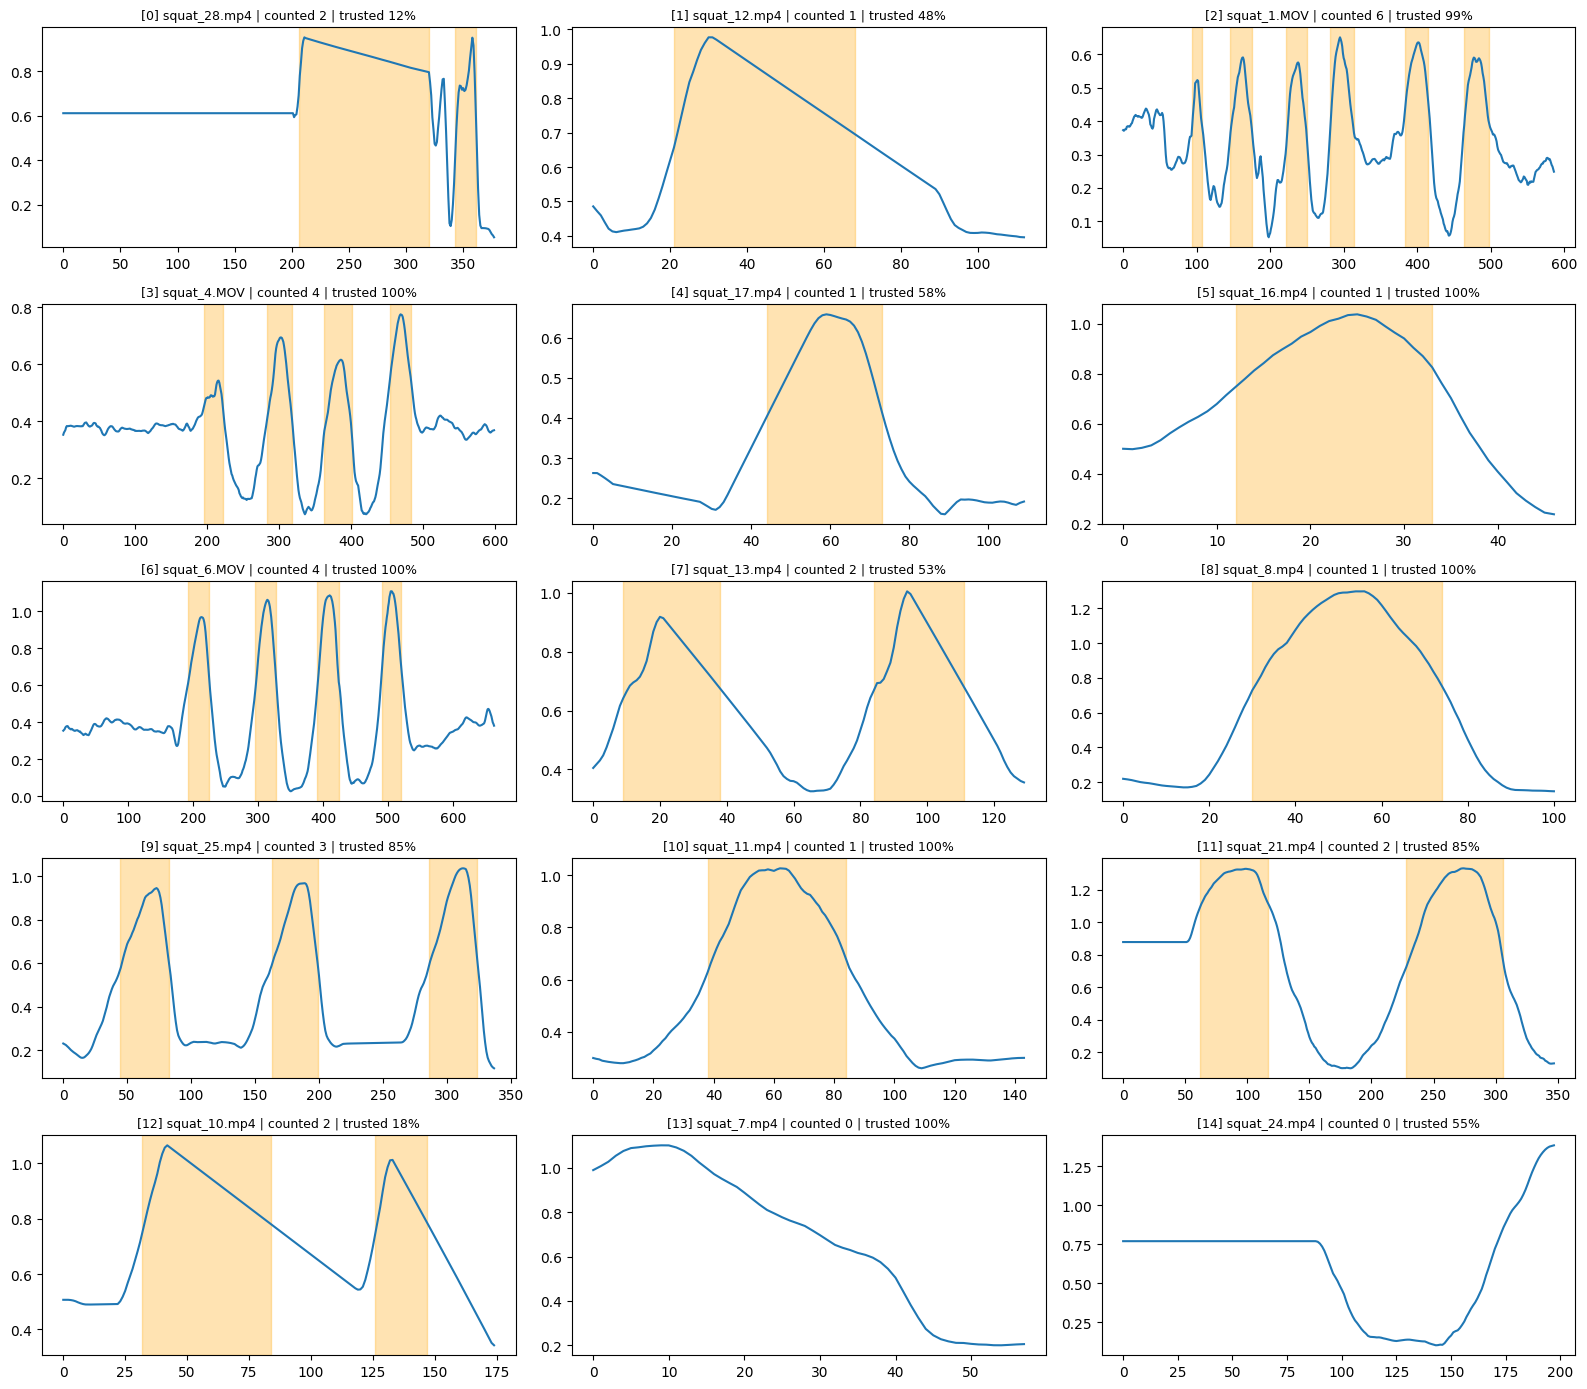

In [44]:
fig, axes = plt.subplots(5, 3, figsize=(16, 14))

for ax, (i, r) in zip(axes.flat, res.iterrows()):
    if r['depth'] is not None:
        ax.plot(r['depth'])
        for s, e in r['reps']:
            ax.axvspan(s, e, color='orange', alpha=0.3)
    ax.set_title(f'[{i}] {r["video"]} | counted {r["count"]} | trusted {r["trusted"]:.0%}', fontsize=9)

plt.tight_layout()
plt.show()


### Watch video example

In [48]:
def watch(i):
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', batch[i],
                    '-vf', 'scale=360:-2,fps=15', '-an', '-vcodec', 'libx264',
                    '-crf', '32', '-pix_fmt', 'yuv420p', '-preset', 'veryfast', 'preview.mp4'])
    print(f'[{i}] {res.loc[i, "video"]} → counter says {res.loc[i, "count"]}')
    return Video('preview.mp4', embed=True, width=360)

watch(6)
# Change the number (0 → 1 → 2 ... → 14) and re-run THIS same cell each time.
# 1st video does not show the full body
# 2nd ✅ | 
# 3rd also not full body but counted 5 correct is 6
# 4th ✅
# 5th this is not squat actually so it did not count✅
# 6th ✅ the rest is all ✅



[6] squat_6.MOV → counter says 4


In [50]:
actual = [None, 1, 6, 4, 0, 1, 4, 2, 1, 3, 1, 2, 0, 0, None]
# Replace the two None values with the real number of squats:

res['actual'] = actual
res['error'] = res['count'] - res['actual']

print(f'Exact match: {(res["error"] == 0).mean():.0%}')
print(f'Within ±1:   {(res["error"].abs() <= 1).mean():.0%}')
print(f'Avg error:   {res["error"].abs().mean():.2f} reps')
res[['video', 'sec', 'trusted', 'actual', 'count', 'error']]


Exact match: 73%
Within ±1:   80%
Avg error:   0.23 reps


,video,sec,trusted,actual,count,error
0,squat_28.mp4,12.612600,0.119048,NaN,2,NaN
1,squat_12.mp4,4.713042,0.477876,1.0,1,0.0
2,squat_1.MOV,19.583333,0.991482,6.0,6,0.0
3,squat_4.MOV,20.018333,1.000000,4.0,4,0.0
4,squat_17.mp4,4.400000,0.581818,0.0,1,1.0
5,squat_16.mp4,1.960292,1.000000,1.0,1,0.0
6,squat_6.MOV,22.153333,1.000000,4.0,4,0.0
7,squat_13.mp4,5.422083,0.530769,2.0,2,0.0
8,squat_8.mp4,4.212542,1.000000,1.0,1,0.0
9,squat_25.mp4,11.277933,0.852071,3.0,3,0.0


In [51]:
path = batch[2]

for stride in [1, 2]:
    with quiet():
        df_s, fps_s, w_s, h_s, _ = extract_landmarks(path, stride=stride)
    depth_s, trusted_s = squat_depth(df_s, w_s, h_s, fps_s)

    reps_s, depths_s = count_reps_peaks(depth_s, fps_s)
    print(f'stride={stride}: counted {len(reps_s)} | rep depths: {[round(d, 2) for d in depths_s]}')

    _, props_all = find_peaks(depth_s, prominence=0.05, distance=max(int(fps_s * 0.8), 1))
    print(f'   every bump ≥ 0.05: {[round(p, 2) for p in props_all["prominences"]]}')


stride=1: counted 6 | rep depths: [np.float64(0.27), np.float64(0.45), np.float64(0.47), np.float64(0.59), np.float64(0.37), np.float64(0.38)]
   every bump ≥ 0.05: [np.float64(0.07), np.float64(0.27), np.float64(0.45), np.float64(0.07), np.float64(0.47), np.float64(0.59), np.float64(0.37), np.float64(0.38)]


KeyboardInterrupt: 

In [52]:
MIN_TRUSTED = 0.30

def count_squats(video_path):
    df, fps, w, h, dur = extract_landmarks(video_path)
    depth, trusted = squat_depth(df, w, h, fps)
    base = {'fps': fps, 'trusted': trusted, 'sec': dur}

    if depth is None or trusted < MIN_TRUSTED:
        return {**base, 'status': 'low_visibility', 'count': None, 'reps': [], 'depth': None,
                'message': 'Step back so your whole body (hips and knees) is visible.'}

    reps, depths = count_reps_peaks(depth, fps)
    return {**base, 'status': 'ok', 'count': len(reps), 'reps': reps, 'depths': depths, 'depth': depth,
            'message': f'{len(reps)} squats counted'}

res['status'] = np.where(res['trusted'] < MIN_TRUSTED, 'low_visibility', 'ok')
res[['video', 'trusted', 'status', 'actual', 'count']]


,video,trusted,status,actual,count
0,squat_28.mp4,0.119048,low_visibility,NaN,2
1,squat_12.mp4,0.477876,ok,1.0,1
2,squat_1.MOV,0.991482,ok,6.0,6
3,squat_4.MOV,1.000000,ok,4.0,4
4,squat_17.mp4,0.581818,ok,0.0,1
5,squat_16.mp4,1.000000,ok,1.0,1
6,squat_6.MOV,1.000000,ok,4.0,4
7,squat_13.mp4,0.530769,ok,2.0,2
8,squat_8.mp4,1.000000,ok,1.0,1
9,squat_25.mp4,0.852071,ok,3.0,3


## Rule-based form report per rep (depth, knees caving in, tempo)

In [53]:
def depth_grade(bottom_depth):
    if bottom_depth >= 0.9:
        return '✅ good depth'
    if bottom_depth >= 0.6:
        return '⚠️ almost, go a little lower'
    return '❌ too shallow, go lower'

def depth_report(video_result):
    rows = []
    for rep_number, (start_frame, end_frame) in enumerate(video_result['reps'], 1):
        depth_during_rep = video_result['depth'][start_frame:end_frame + 1]
        bottom_depth = float(np.max(depth_during_rep))
        rows.append({
            'rep': rep_number,
            'bottom_depth': round(bottom_depth, 2),
            'feedback': depth_grade(bottom_depth),
        })
    return pd.DataFrame(rows)

for video_index in [2, 6]:
    print(f'\n🎬 [{video_index}] {res.loc[video_index, "video"]}')
    print(depth_report(res.loc[video_index]).to_string(index=False))



🎬 [2] squat_1.MOV
 rep  bottom_depth                     feedback
   1          0.52      ❌ too shallow, go lower
   2          0.59      ❌ too shallow, go lower
   3          0.58      ❌ too shallow, go lower
   4          0.65 ⚠️ almost, go a little lower
   5          0.64 ⚠️ almost, go a little lower
   6          0.59      ❌ too shallow, go lower

🎬 [6] squat_6.MOV
 rep  bottom_depth     feedback
   1          0.97 ✅ good depth
   2          1.06 ✅ good depth
   3          1.09 ✅ good depth
   4          1.11 ✅ good depth


In [54]:
def count_squats(video_path):
    landmarks, fps, width, height, seconds = extract_landmarks(video_path)
    depth, trusted = squat_depth(landmarks, width, height, fps)
    base = {
        'fps': fps,
        'trusted': trusted,
        'sec': seconds,
        'landmarks': landmarks,
        'width': width,
        'height': height,
    }

    if depth is None or trusted < MIN_TRUSTED:
        return {**base, 'status': 'low_visibility', 'count': None, 'reps': [], 'depth': None,
                'message': 'Step back so your whole body (hips and knees) is visible.'}

    reps, rep_depths = count_reps_peaks(depth, fps)
    return {**base, 'status': 'ok', 'count': len(reps), 'reps': reps, 'depths': rep_depths, 'depth': depth,
            'message': f'{len(reps)} squats counted'}

detailed_results = {}
for video_index in [2, 6]:
    with quiet():
        detailed_results[video_index] = count_squats(batch[video_index])
    result = detailed_results[video_index]
    print(f'[{video_index}] {res.loc[video_index, "video"]} → {result["message"]} | body points table: {result["landmarks"].shape}')


[2] squat_1.MOV → 6 squats counted | body points table: (587, 133)
[6] squat_6.MOV → 4 squats counted | body points table: (664, 133)


In [55]:
def knee_grade(knee_to_hip_ratio):
    if np.isnan(knee_to_hip_ratio):
        return '❔ knees not visible'
    if knee_to_hip_ratio >= 0.9:
        return '✅ knees in line'
    if knee_to_hip_ratio >= 0.75:
        return '⚠️ knees caving in slightly, push them out'
    return '❌ knees caving in, push them out'

def knee_report(video_result):
    landmarks = video_result['landmarks']
    width, height = video_result['width'], video_result['height']

    def point_x(point_number):
        return landmarks[f'{point_number}_x'] * width
    def point_y(point_number):
        return landmarks[f'{point_number}_y'] * height

    shoulder_width = (point_x(11) - point_x(12)).abs()
    hip_width = (point_x(23) - point_x(24)).abs()
    knee_width = (point_x(25) - point_x(26)).abs()

    shoulder_middle_x = (point_x(11) + point_x(12)) / 2
    shoulder_middle_y = (point_y(11) + point_y(12)) / 2
    hip_middle_x = (point_x(23) + point_x(24)) / 2
    hip_middle_y = (point_y(23) + point_y(24)) / 2
    torso_length = np.hypot(shoulder_middle_x - hip_middle_x, shoulder_middle_y - hip_middle_y)

    view_ratio = (shoulder_width / torso_length).median()
    if view_ratio < 0.5:
        return None, view_ratio

    rows = []
    for rep_number, (start_frame, end_frame) in enumerate(video_result['reps'], 1):
        depth_during_rep = video_result['depth'][start_frame:end_frame + 1]
        bottom_frame = start_frame + int(np.argmax(depth_during_rep))
        knee_to_hip_ratio = knee_width.iloc[bottom_frame] / hip_width.iloc[bottom_frame]
        rows.append({
            'rep': rep_number,
            'knee_to_hip': round(float(knee_to_hip_ratio), 2),
            'feedback': knee_grade(knee_to_hip_ratio),
        })
    return pd.DataFrame(rows), view_ratio

for video_index in [2, 6]:
    report, view_ratio = knee_report(detailed_results[video_index])
    print(f'\n🎬 [{video_index}] {res.loc[video_index, "video"]} | shoulder/torso = {view_ratio:.2f}')
    if report is None:
        print('   Side view → knee check skipped (it needs a front or back view)')
    else:
        print(report.to_string(index=False))



🎬 [2] squat_1.MOV | shoulder/torso = 0.71
 rep  knee_to_hip        feedback
   1         1.29 ✅ knees in line
   2         1.75 ✅ knees in line
   3         1.84 ✅ knees in line
   4         1.78 ✅ knees in line
   5         1.79 ✅ knees in line
   6         1.86 ✅ knees in line

🎬 [6] squat_6.MOV | shoulder/torso = 0.67
 rep  knee_to_hip        feedback
   1         2.34 ✅ knees in line
   2         2.54 ✅ knees in line
   3         2.54 ✅ knees in line
   4         2.56 ✅ knees in line


### Tempo per rep (down / up / total seconds)
**What:** Times each squat: going down (start → bottom) and coming up (bottom → finish), measured at 80% of the bump's height.

**Needed by:** the form report cell below (`form_report` calls `tempo_report`).

In [62]:
from scipy.signal import peak_widths

def tempo_report(video_result):
    depth = video_result['depth']
    fps = video_result['fps']
    rows = []
    for rep_number, (start_frame, end_frame) in enumerate(video_result['reps'], 1):
        depth_during_rep = depth[start_frame:end_frame + 1]
        bottom_frame = start_frame + int(np.argmax(depth_during_rep))
        # Finds the deepest moment of this rep (same as the knee check).

        _, _, rep_begin, rep_finish = peak_widths(depth, [bottom_frame], rel_height=0.8)
        rep_begin, rep_finish = float(rep_begin[0]), float(rep_finish[0])
        # Measures where the rep really starts and finishes, at 80% of the bump's height.

        down_seconds = (bottom_frame - rep_begin) / fps
        up_seconds = (rep_finish - bottom_frame) / fps
        total_seconds = down_seconds + up_seconds
        rows.append({
            'rep': rep_number,
            'down_s': round(down_seconds, 2),
            'up_s': round(up_seconds, 2),
            'total_s': round(total_seconds, 2),
            'feedback': tempo_grade(down_seconds, total_seconds),
        })
    return pd.DataFrame(rows)
# Frames ÷ frames per second = seconds. tempo_grade (defined in the next cell) turns the times into feedback.

In [58]:
def tempo_grade(down_seconds, total_seconds):
    if total_seconds < 1.0:
        return '⚠️ too fast, slow the whole rep down'
    if down_seconds < 0.7:
        return '⚠️ dropping too fast, control the way down'
    return '✅ controlled'

def form_report(video_result):
    depth_table = depth_report(video_result)
    tempo_table = tempo_report(video_result)
    report = pd.DataFrame({
        'rep': depth_table['rep'],
        'depth': depth_table['feedback'],
        'tempo': tempo_table['feedback'],
    })

    good_depth = depth_table['feedback'].str.startswith('✅').sum()
    controlled = tempo_table['feedback'].str.startswith('✅').sum()
    total_reps = len(report)
    summary = f'{total_reps} reps · {good_depth}/{total_reps} good depth · {controlled}/{total_reps} controlled'
    return report, summary

for video_index in [2, 6]:
    report, summary = form_report(detailed_results[video_index])
    print(f'\n🎬 [{video_index}] {res.loc[video_index, "video"]}')
    print(f'   {summary}')
    print(report.to_string(index=False))



🎬 [2] squat_1.MOV
   6 reps · 0/6 good depth · 3/6 controlled
 rep                        depth                                      tempo
   1      ❌ too shallow, go lower       ⚠️ too fast, slow the whole rep down
   2      ❌ too shallow, go lower                               ✅ controlled
   3      ❌ too shallow, go lower                               ✅ controlled
   4 ⚠️ almost, go a little lower ⚠️ dropping too fast, control the way down
   5 ⚠️ almost, go a little lower                               ✅ controlled
   6      ❌ too shallow, go lower ⚠️ dropping too fast, control the way down

🎬 [6] squat_6.MOV
   4 reps · 4/4 good depth · 3/4 controlled
 rep        depth                                      tempo
   1 ✅ good depth                               ✅ controlled
   2 ✅ good depth                               ✅ controlled
   3 ✅ good depth                               ✅ controlled
   4 ✅ good depth ⚠️ dropping too fast, control the way down


## Download the dataset into Kaggle 

In [69]:
!mkdir -p /kaggle/temp
!df -h /kaggle/temp | tail -1

!wget -q -O /kaggle/temp/mendeley.zip "https://data.mendeley.com/public-api/zip/kgbb3yn47p/download/2"

!ls -lh /kaggle/temp/mendeley.zip


overlay         8.0T  7.1T  967G  89% /
-rw-r--r-- 1 root root 7.1G Jul 13 05:30 /kaggle/temp/mendeley.zip


In [70]:
import zipfile
from collections import Counter

zip_path = '/kaggle/temp/mendeley.zip'
with zipfile.ZipFile(zip_path) as archive:
    all_names = archive.namelist()
file_names = [name for name in all_names if not name.endswith('/')]
print(f'{len(file_names)} files in the zip')

extension_counts = Counter(os.path.splitext(name)[1].lower() for name in file_names)
print('File types:', dict(extension_counts))

folder_counts = Counter('/'.join(name.split('/')[:3]) for name in file_names)
print(f'\n{len(folder_counts)} folders (showing the first 40):')
for folder, count in sorted(folder_counts.items())[:40]:
    print(f'{count:5} files  {folder}')
# Groups files by their first 3 folder levels and counts how many files each one has.
# Limited to 40 lines so we don't flood the page (and crash the tab again).

3127 files in the zip
File types: {'.md': 1, '.mp4': 3126}

41 folders (showing the first 40):
  150 files  A Multi-View Raw Video Dataset of Seven Fitness Ex/Dataset Exercise Quality-wise/abs
  144 files  A Multi-View Raw Video Dataset of Seven Fitness Ex/Dataset Exercise Quality-wise/back
  150 files  A Multi-View Raw Video Dataset of Seven Fitness Ex/Dataset Exercise Quality-wise/bicep_curl
  144 files  A Multi-View Raw Video Dataset of Seven Fitness Ex/Dataset Exercise Quality-wise/push_up
  150 files  A Multi-View Raw Video Dataset of Seven Fitness Ex/Dataset Exercise Quality-wise/shoulder
  150 files  A Multi-View Raw Video Dataset of Seven Fitness Ex/Dataset Exercise Quality-wise/squat
  154 files  A Multi-View Raw Video Dataset of Seven Fitness Ex/Dataset Exercise Quality-wise/tricep
  150 files  A Multi-View Raw Video Dataset of Seven Fitness Ex/Dataset Exercise-wise/abs
  144 files  A Multi-View Raw Video Dataset of Seven Fitness Ex/Dataset Exercise-wise/back
  150 files  A M

In [72]:
with zipfile.ZipFile(zip_path) as archive:
    readme_name = [name for name in file_names if name.endswith('.md')][0]
    print(archive.read(readme_name).decode('utf-8')[:3000])
# Prints the dataset's README (first 3,000 characters).
# It usually explains how the files are named and what the labels mean.

squat_quality_files = [name for name in file_names if 'Exercise Quality-wise/squat/' in name]
print(f'\n--- {len(squat_quality_files)} squat files in the Quality-wise layout. First 10: ---')
for name in sorted(squat_quality_files)[:10]:
    print(name.split('Exercise Quality-wise/')[1])
# Lists 10 squat file paths (with the long start of the path cut off, so they're easy to read).
# We're looking for: good/bad, camera view and the person ID in each name.

# Multi-View Fitness Exercise Video Dataset

## Dataset Overview

This repository contains a multi-view fitness exercise video dataset collected for research in exercise recognition, human action analysis, posture assessment, and good/bad exercise form classification.

The dataset includes videos captured from three different camera viewpoints for multiple participants performing seven common fitness exercises with both correct and incorrect execution.

---

## Dataset Statistics

- Number of Subjects: 26
- Number of Exercise Categories: 7
- Exercise Classes:
  - Abs
  - Back
  - Bicep Curl
  - Push-up
  - Shoulder
  - Squat
  - Tricep

- Exercise Form:
  - Good
  - Bad

- Camera Views:
  - Front
  - Side
  - Diagonal

- Video Format: MP4

---

# Dataset Organizations

To support different research workflows, the dataset is provided in three folder organizations.

---

## 1. Dataset Subject-wise

Folder Structure

Dataset Subject-wise/

    subject_001/
        abs/
            good/
 

In [73]:
EXTRACT_DIR = '/kaggle/temp/mendeley'
LAYOUT = 'Exercise Quality-wise/'

with zipfile.ZipFile(zip_path) as archive:
    quality_files = [name for name in file_names if LAYOUT in name]
    for name in quality_files:
        archive.extract(name, EXTRACT_DIR)
print(f'Extracted {len(quality_files)} videos')

labels = []
for name in quality_files:
    file_name = os.path.basename(name).replace('.mp4', '')
    parts = file_name.split('_')
    labels.append({
        'subject': int(parts[1]),
        'exercise': '_'.join(parts[2:-2]),
        'quality': parts[-2],
        'view': parts[-1],
        'path': os.path.join(EXTRACT_DIR, name),
    })
labels = pd.DataFrame(labels)

labels.to_csv('/kaggle/working/mendeley_labels.csv', index=False)
print(pd.crosstab(labels['exercise'], labels['quality']))
print(f'\nViews: {labels["view"].value_counts().to_dict()} | People: {labels["subject"].nunique()}')


Extracted 1042 videos
quality     bad  good
exercise             
abs          75    75
back         72    72
bicep         0     1
bicep_curl   75    74
push_up      72    72
shoulder     75    75
squat        75    75
tricep       77    77

Views: {'diagonal': 348, 'front': 348, 'side': 346} | People: 26


In [74]:
print(labels.loc[labels['exercise'] == 'bicep', 'path'].values)

labels['exercise'] = labels['exercise'].replace({'bicep': 'bicep_curl'})
labels.to_csv('/kaggle/working/mendeley_labels.csv', index=False)
print(pd.crosstab(labels['exercise'], labels['quality']))
# Renames "bicep" → "bicep_curl", saves the fixed table again and prints the counts.
# bicep_curl should now show 75 bad + 75 good, and the "bicep" row should be gone.

['/kaggle/temp/mendeley/A Multi-View Raw Video Dataset of Seven Fitness Ex/Dataset Exercise Quality-wise/bicep_curl/good/subject_003_bicep_good_side.mp4']
quality     bad  good
exercise             
abs          75    75
back         72    72
bicep_curl   75    75
push_up      72    72
shoulder     75    75
squat        75    75
tricep       77    77


## (measure the total video length)

In [75]:
durations = []
for video_path in labels['path']:
    capture = cv2.VideoCapture(video_path)
    frame_count = capture.get(cv2.CAP_PROP_FRAME_COUNT)
    frames_per_second = capture.get(cv2.CAP_PROP_FPS) or 30
    durations.append(frame_count / frames_per_second)
    capture.release()
labels['seconds'] = durations

summary = labels.groupby('exercise')['seconds'].agg(['count', 'mean', 'sum']).round(1)
summary['total_minutes'] = (summary['sum'] / 60).round(1)
print(summary[['count', 'mean', 'total_minutes']])
print(f'\nAll videos: {labels["seconds"].sum() / 60:.0f} minutes of video')


            count  mean  total_minutes
exercise                              
abs           150  29.5           73.7
back          144  29.3           70.3
bicep_curl    150  31.3           78.3
push_up       144  20.8           50.0
shoulder      150  29.5           73.8
squat         150  29.6           74.1
tricep        154  29.2           74.9

All videos: 495 minutes of video


## (speed test on one video)

In [76]:
import time

test_video = labels[labels['exercise'] == 'squat']['path'].iloc[0]
test_seconds = labels[labels['exercise'] == 'squat']['seconds'].iloc[0]

for stride in [1, 2]:
    start_time = time.time()
    with quiet():
        landmarks, *_ = extract_landmarks(test_video, stride=stride)
    elapsed = time.time() - start_time
    print(f'stride={stride}: {elapsed:.0f}s to process a {test_seconds:.0f}s video '
          f'→ {elapsed / test_seconds:.2f}× real time')


stride=1: 13s to process a 32s video → 0.40× real time
stride=2: 7s to process a 32s video → 0.20× real time


## (extract body points for phase 1)

In [77]:
LANDMARK_DIR = '/kaggle/working/landmarks'
os.makedirs(LANDMARK_DIR, exist_ok=True)
phase1 = labels[labels['exercise'].isin(['squat', 'bicep_curl', 'push_up'])].reset_index(drop=True)
print(f'{len(phase1)} videos to process')

start_time = time.time()
newly_processed = 0
for number, row in enumerate(phase1.itertuples(), 1):
    output_path = os.path.join(LANDMARK_DIR, os.path.basename(row.path).replace('.mp4', '.parquet'))

    if not os.path.exists(output_path):
        with quiet():
            landmarks, fps, width, height, seconds = extract_landmarks(row.path, stride=1)
        landmarks['fps'] = fps
        landmarks['width'] = width
        landmarks['height'] = height
        landmarks.to_parquet(output_path)
        newly_processed += 1

    if number % 25 == 0 or number == len(phase1):
        minutes_so_far = (time.time() - start_time) / 60
        print(f'{number}/{len(phase1)} done | {newly_processed} new | {minutes_so_far:.0f} min elapsed')
    # A progress line every 25 videos, plus one at the very end.

444 videos to process
25/444 done | 25 new | 6 min elapsed
50/444 done | 50 new | 11 min elapsed
75/444 done | 75 new | 16 min elapsed
100/444 done | 100 new | 21 min elapsed
125/444 done | 125 new | 26 min elapsed
150/444 done | 150 new | 31 min elapsed
175/444 done | 175 new | 35 min elapsed
200/444 done | 200 new | 38 min elapsed
225/444 done | 225 new | 42 min elapsed
250/444 done | 250 new | 46 min elapsed
275/444 done | 275 new | 49 min elapsed
300/444 done | 300 new | 53 min elapsed
325/444 done | 325 new | 58 min elapsed
350/444 done | 350 new | 63 min elapsed
375/444 done | 375 new | 68 min elapsed
400/444 done | 400 new | 74 min elapsed
425/444 done | 425 new | 78 min elapsed
444/444 done | 444 new | 82 min elapsed


## Check and Pack the results

In [78]:
import glob, shutil

landmark_files = sorted(glob.glob(f'{LANDMARK_DIR}/*.parquet'))
total_megabytes = sum(os.path.getsize(file) for file in landmark_files) / 1e6
print(f'{len(landmark_files)} files | {total_megabytes:.0f} MB in total')
# Counts the saved body-point files and adds up their size.
# Should say 444 files.

example = pd.read_parquet(landmark_files[0])
print(f'Example: {os.path.basename(landmark_files[0])} → {example.shape[0]} frames × {example.shape[1]} columns')
print(f'Frames with a person found: {example["0_vis"].notna().mean():.0%}')
# Opens one file to check it looks right: ~900 frames × 136 columns
# (frame + 132 body-point values + fps, width, height).

shutil.copy('/kaggle/working/mendeley_labels.csv', LANDMARK_DIR)
shutil.make_archive('/kaggle/working/landmarks_phase1', 'zip', LANDMARK_DIR)
print(f'Backup zip: {os.path.getsize("/kaggle/working/landmarks_phase1.zip") / 1e6:.0f} MB')
# Puts the label table next to the body-point files, then packs everything into ONE zip file.
# One zip is much easier to download or save than 445 separate files.

444 files | 197 MB in total
Example: subject_001_bicep_curl_bad_diagonal.parquet → 485 frames × 136 columns
Frames with a person found: 100%
Backup zip: 107 MB
